# 09: Interpretability

SHAP feature importance for the adopted best classical model of all six target/dataset
combinations. Gain-based importance is shown alongside SHAP (the same side-by-side
convention `05`/`05b`/`05c` already use), ranked by SHAP, since gain systematically starves
other features' credit when one feature dominates early splits (the PM100 node-count finding
those notebooks already document).

**Every model used here is either the original saved fit, or a fresh refit whose test R2 is
verified against the already-adopted value (within 0.001) before any SHAP is computed.**
`fdata_power` (XGBoost) and `pm100_duration` (LightGBM) reuse their saved fitted model object
directly -- no refit. `pm100_power` and `pm100_memory_c4` (both XGBoost) are refit below, on
the full training split, timed for real; the refit cost is well under a minute either way.
`fdata_duration` (XGBoost) and `fdata_memory` (LightGBM) are refit in a separate process
(`scripts/notebook09_interpretability/refit_and_verify.py`), one at a time under
`systemd-run --user --scope` per this project's F-DATA memory-safety convention, on the FULL
16,315,867-row training split (not a sample), with the fit timed for real rather than
estimated from historical numbers. All four refits are checked against the adopted test R2
before being trusted for anything downstream; a failing check would stop this notebook before
computing SHAP, not after.

In [1]:
import sys
sys.path.append("..")

import pathlib
import time
import warnings

warnings.filterwarnings("ignore")  # suppresses an unrelated tqdm/ipywidgets notice shap's import triggers

import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import r2_score
from xgboost import XGBRegressor

from src import plotting

INTERIM_DIR = pathlib.Path("../data/interim")
RESULTS_DIR = pathlib.Path("../results")
FIGURES_DIR = pathlib.Path("figures")

SEED = 0
SHAP_SAMPLE = 200_000  # F-DATA only; PM100 combinations use the full test set (all under 200k rows)
R2_CHECK_TOL = 0.001
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

## Refit and verify: pm100_power, pm100_memory_c4

Both refit on the full training split (126,217 rows), XGBoost, `tree_method="hist"`, the
already-adopted `best_params`, seed 0 -- no new search. Saved to `data/interim/` (gitignored)
so `08b` can load the same fitted model without refitting again.

In [2]:
PM100_REFIT_COMBOS = {
    "pm100_power": dict(prepared="pm100_power_prepared.joblib", model_name="XGBoost",
                         tree_method="hist", out_file="pm100_power_xgb_result.joblib",
                         adopted_r2=0.9243),
    "pm100_memory_c4": dict(prepared="pm100_memory_clean4_prepared.joblib", model_name="XGBoost",
                             tree_method="hist", out_file="pm100_memory_c4_xgb_result.joblib",
                             adopted_r2=0.9658),
}

refit_check_rows = []
for combo, cfg in PM100_REFIT_COMBOS.items():
    t0 = time.perf_counter()
    prep = joblib.load(INTERIM_DIR / cfg["prepared"])
    params = prep["best_params"][cfg["model_name"]]
    m = XGBRegressor(**params, tree_method=cfg["tree_method"], n_jobs=-1, random_state=SEED)
    m.fit(prep["X_train"], prep["y_train"])
    fit_seconds = time.perf_counter() - t0

    pred_log = np.asarray(m.predict(prep["X_test"]), dtype=float)
    pred_raw = np.expm1(pred_log)
    refit_r2 = r2_score(prep["y_test_raw"], pred_raw)
    diff = abs(refit_r2 - cfg["adopted_r2"])
    passed = diff < R2_CHECK_TOL

    print(f"{combo}: refit {cfg['model_name']} on {len(prep['X_train']):,} rows in "
          f"{fit_seconds:.1f}s | refit test raw R2={refit_r2:.6f} vs adopted="
          f"{cfg['adopted_r2']} | diff={diff:.6f} | within {R2_CHECK_TOL}: {passed}")
    assert passed, f"{combo}: refit R2 does not match the adopted value within {R2_CHECK_TOL}"

    joblib.dump(dict(model_name=cfg["model_name"], model=m, best_params=params,
                      tree_method=cfg["tree_method"], fit_seconds=fit_seconds,
                      refit_test_r2=float(refit_r2), adopted_r2=cfg["adopted_r2"],
                      r2_check_diff=float(diff)),
                INTERIM_DIR / cfg["out_file"])
    refit_check_rows.append(dict(combo=combo, model=cfg["model_name"], fit_seconds=fit_seconds,
                                  refit_r2=refit_r2, adopted_r2=cfg["adopted_r2"], diff=diff,
                                  passed=passed))

display(pd.DataFrame(refit_check_rows).set_index("combo"))

pm100_power: refit XGBoost on 126,217 rows in 35.5s | refit test raw R2=0.924327 vs adopted=0.9243 | diff=0.000027 | within 0.001: True


pm100_memory_c4: refit XGBoost on 126,217 rows in 125.6s | refit test raw R2=0.965823 vs adopted=0.9658 | diff=0.000023 | within 0.001: True


,model,fit_seconds,refit_r2,adopted_r2,diff,passed
combo,,,,,,
pm100_power,XGBoost,35.485720,0.924327,0.9243,0.000027,True
pm100_memory_c4,XGBoost,125.622098,0.965823,0.9658,0.000023,True


## Load and verify: fdata_duration, fdata_memory

Refit separately, one at a time, each under its own `systemd-run --user --scope`, on the
FULL 16,315,867-row training split (`scripts/notebook09_interpretability/refit_and_verify.py`
-- real measured fit time, not an estimate from a sample or from historical numbers). Loaded
here, not refit again; the R2 check that script already ran is re-asserted below rather than
trusted blindly.

In [3]:
FDATA_REFIT_FILES = {
    "fdata_duration": "fdata_duration_xgb_result.joblib",
    "fdata_memory": "fdata_memory_lgbm_result.joblib",
}

for combo, fname in FDATA_REFIT_FILES.items():
    obj = joblib.load(INTERIM_DIR / fname)
    print(f"{combo}: real fit on the FULL training split (systemd-run, measured, not "
          f"extrapolated) took {obj['fit_seconds']:.1f}s ({obj['model_name']}) | "
          f"refit test raw R2={obj['refit_test_r2']:.6f} vs adopted={obj['adopted_r2']} | "
          f"diff={obj['r2_check_diff']:.6f} | within {R2_CHECK_TOL}: "
          f"{obj['r2_check_diff'] < R2_CHECK_TOL}")
    assert obj["r2_check_diff"] < R2_CHECK_TOL, f"{combo}: saved refit R2 check did not pass"
    refit_check_rows.append(dict(combo=combo, model=obj["model_name"], fit_seconds=obj["fit_seconds"],
                                  refit_r2=obj["refit_test_r2"], adopted_r2=obj["adopted_r2"],
                                  diff=obj["r2_check_diff"], passed=True))

display(pd.DataFrame(refit_check_rows).set_index("combo"))

fdata_duration: real fit on the FULL training split (systemd-run, measured, not extrapolated) took 340.2s (XGBoost) | refit test raw R2=0.835891 vs adopted=0.8359 | diff=0.000009 | within 0.001: True
fdata_memory: real fit on the FULL training split (systemd-run, measured, not extrapolated) took 320.2s (LightGBM) | refit test raw R2=0.866805 vs adopted=0.8668 | diff=0.000005 | within 0.001: True


,model,fit_seconds,refit_r2,adopted_r2,diff,passed
combo,,,,,,
pm100_power,XGBoost,35.485720,0.924327,0.9243,0.000027,True
pm100_memory_c4,XGBoost,125.622098,0.965823,0.9658,0.000023,True
fdata_duration,XGBoost,340.175508,0.835891,0.8359,0.000009,True
fdata_memory,LightGBM,320.213801,0.866805,0.8668,0.000005,True


In [4]:
def gain_importance_for(model, model_name, columns):
    if model_name == "LightGBM":
        return pd.Series(model.booster_.feature_importance(importance_type="gain"), index=columns)
    if model_name == "XGBoost":
        return pd.Series(model.get_booster().get_score(importance_type="gain")).reindex(columns).fillna(0.0)
    if model_name == "RandomForest":
        return pd.Series(model.feature_importances_, index=columns)
    raise ValueError(model_name)


def compute_shap_table(combo, model, model_name, X_train_columns, X_test, dataset):
    sample_n = min(SHAP_SAMPLE, len(X_test)) if dataset == "fdata" else len(X_test)
    si = np.random.RandomState(SEED).permutation(len(X_test))[:sample_n]
    X_shap = X_test.iloc[si]

    gain_importance = gain_importance_for(model, model_name, X_train_columns)
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_shap)
    shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X_train_columns)
    print(f"{combo}: SHAP computed on {sample_n:,} of {len(X_test):,} test rows ({model_name})")

    fig = plotting.plot_feature_importance_comparison(
        gain_importance, shap_importance,
        f"{combo} -- {model_name} feature importance (top 10)", top_n=10,
    )
    fig.savefig(FIGURES_DIR / f"notebook09_{combo}_feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()

    total_shap = shap_importance.sum()
    top10 = shap_importance.sort_values(ascending=False).head(10)
    return [dict(combo=combo, model=model_name, rank=i + 1, feature=feat,
                 mean_abs_shap=val, share_of_total_pct=100 * val / total_shap)
            for i, (feat, val) in enumerate(top10.items())]

fdata_power: SHAP computed on 200,000 of 6,992,514 test rows (XGBoost)


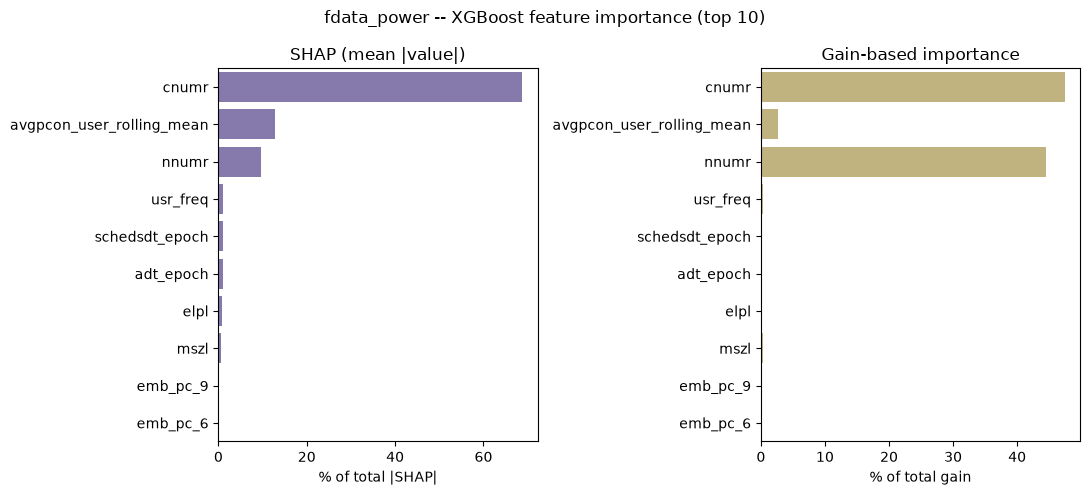

fdata_duration: SHAP computed on 200,000 of 6,992,514 test rows (XGBoost)


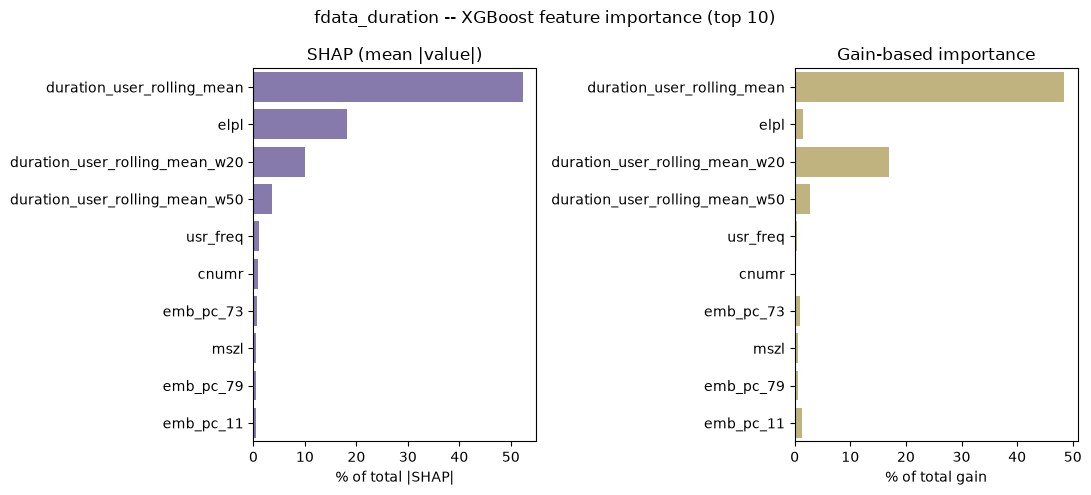

fdata_memory: SHAP computed on 200,000 of 6,992,514 test rows (LightGBM)


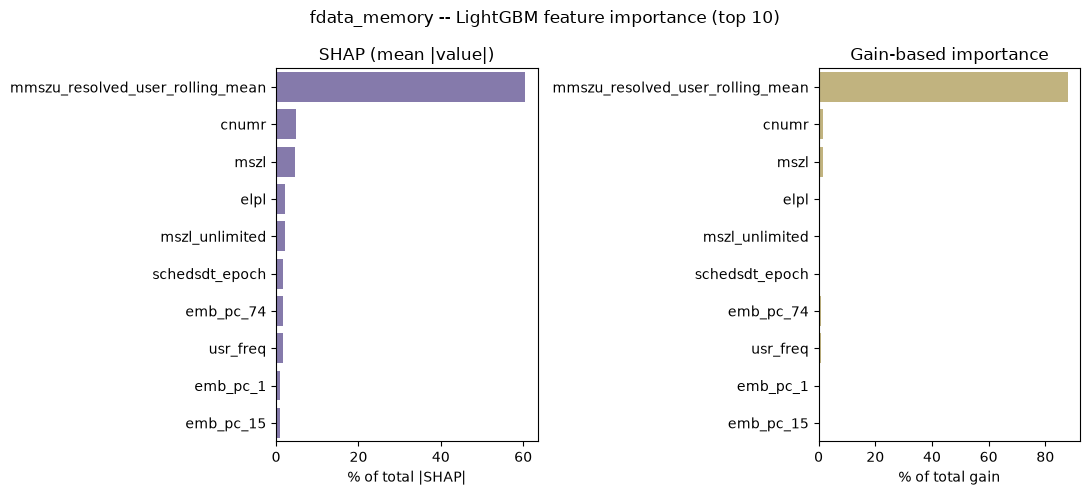

pm100_duration: SHAP computed on 54,093 of 54,093 test rows (LightGBM)


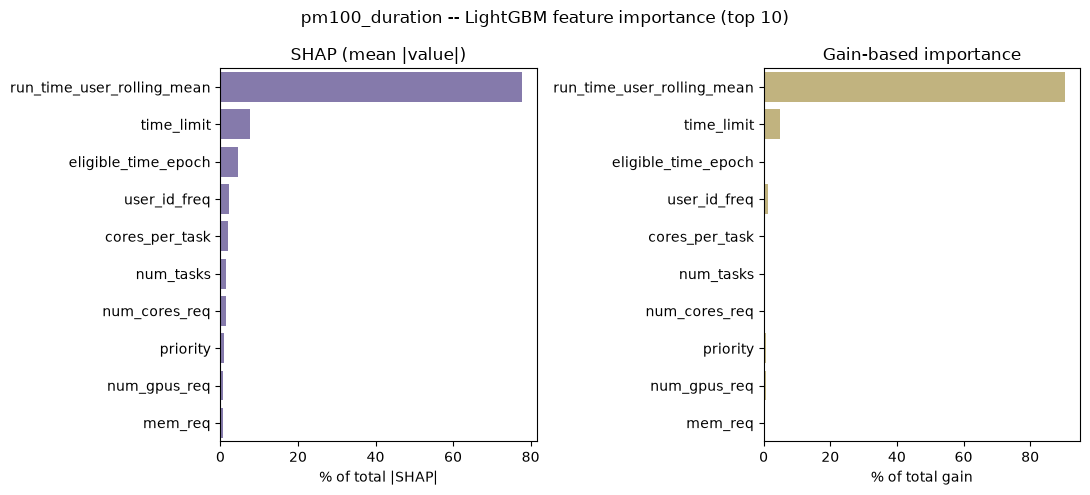

pm100_power: SHAP computed on 54,093 of 54,093 test rows (XGBoost)


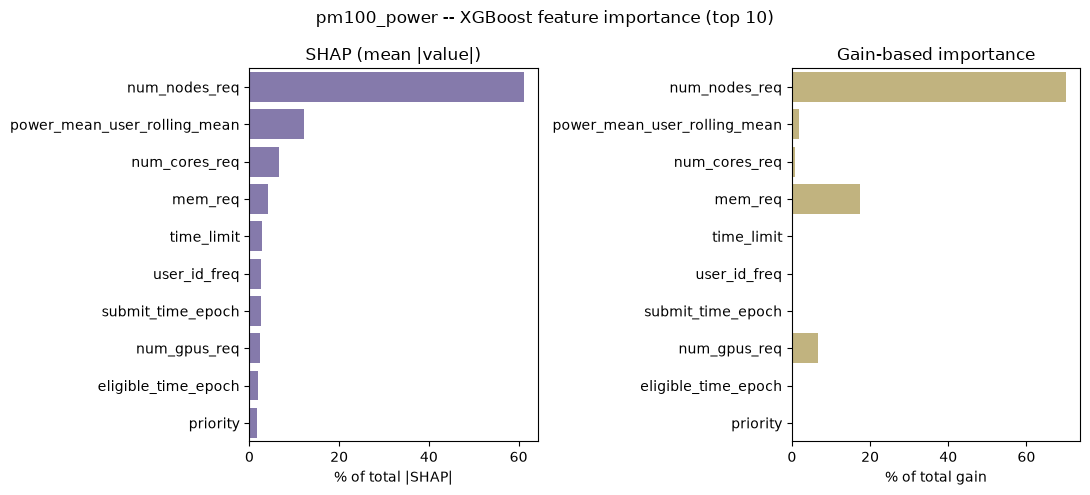

pm100_memory_c4: SHAP computed on 54,093 of 54,093 test rows (XGBoost)


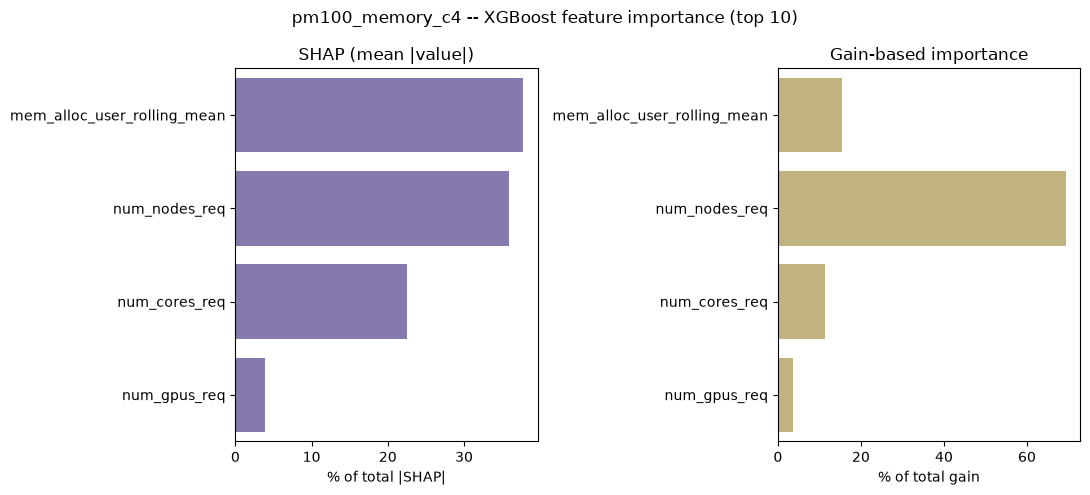

In [5]:
ALL_COMBOS_TO_RUN = {
    "fdata_power": dict(source="saved", joblib="fdata_power_xgb_result.joblib",
                         prepared="fdata_power_prepared.joblib", dataset="fdata"),
    "fdata_duration": dict(source="saved", joblib="fdata_duration_xgb_result.joblib",
                            prepared="fdata_duration_r2_prepared.joblib", dataset="fdata"),
    "fdata_memory": dict(source="saved", joblib="fdata_memory_lgbm_result.joblib",
                          prepared="fdata_memory_prepared.joblib", dataset="fdata"),
    "pm100_duration": dict(source="saved", joblib="pm100_duration_lgbm_result.joblib",
                            prepared="pm100_duration_prepared.joblib", dataset="pm100"),
    "pm100_power": dict(source="saved", joblib="pm100_power_xgb_result.joblib",
                         prepared="pm100_power_prepared.joblib", dataset="pm100"),
    "pm100_memory_c4": dict(source="saved", joblib="pm100_memory_c4_xgb_result.joblib",
                             prepared="pm100_memory_clean4_prepared.joblib", dataset="pm100"),
}

all_top10_rows = []
for combo, cfg in ALL_COMBOS_TO_RUN.items():
    obj = joblib.load(INTERIM_DIR / cfg["joblib"])
    model = obj["model"]
    model_name = obj["model_name"]
    prep = joblib.load(INTERIM_DIR / cfg["prepared"])
    X_test = prep["X_test"]
    X_train_columns = prep["X_train"].columns
    rows = compute_shap_table(combo, model, model_name, X_train_columns, X_test, cfg["dataset"])
    all_top10_rows.extend(rows)

## Top-10 features by SHAP, all six combinations

In [6]:
top10_table = pd.DataFrame(all_top10_rows).set_index(["combo", "rank"])
display(top10_table.round(4))

model                           feature  mean_abs_shap  share_of_total_pct
combo           rank                                                                               
fdata_power     1      XGBoost                             cnumr         1.0281             68.7864
                2      XGBoost         avgpcon_user_rolling_mean         0.1916             12.8176
                3      XGBoost                             nnumr         0.1432              9.5793
                4      XGBoost                          usr_freq         0.0157              1.0533
                5      XGBoost                    schedsdt_epoch         0.0150              1.0061
                6      XGBoost                         adt_epoch         0.0144              0.9619
                7      XGBoost                              elpl         0.0114              0.7635
                8      XGBoost                              mszl         0.0088              0.5868
                9      XGBoost                          emb_pc_9         0.0031              0.2096
                10     XGBoost                          emb_pc_6         0.0025              0.1696
fdata_duration  1      XGBoost        duration_user_rolling_mean         1.3459             52.3310
                2      XGBoost                              elpl         0.4669             18.1523
                3      XGBoost    duration_user_rolling_mean_w20         0.2579             10.0279
                4      XGBoost    duration_user_rolling_mean_w50         0.0935              3.6367
                5      XGBoost                          usr_freq         0.0291              1.1320
                6      XGBoost                             cnumr         0.0229              0.8902
                7      XGBoost                         emb_pc_73         0.0159              0.6196
                8      XGBoost                              mszl         0.0153              0.5942
                9      XGBoost                         emb_pc_79         0.0125              0.4868
                10     XGBoost                         emb_pc_11         0.0106              0.4115
fdata_memory    1     LightGBM  mmszu_resolved_user_rolling_mean         1.0852             60.4486
                2     LightGBM                             cnumr         0.0857              4.7721
                3     LightGBM                              mszl         0.0803              4.4751
                4     LightGBM                              elpl         0.0403              2.2462
                5     LightGBM                    mszl_unlimited         0.0396              2.2047
                6     LightGBM                    schedsdt_epoch         0.0314              1.7504
                7     LightGBM                         emb_pc_74         0.0293              1.6341
                8     LightGBM                          usr_freq         0.0283              1.5769
                9     LightGBM                          emb_pc_1         0.0165              0.9194
                10    LightGBM                         emb_pc_15         0.0155              0.8611
pm100_duration  1     LightGBM        run_time_user_rolling_mean         2.9433             77.7056
                2     LightGBM                        time_limit         0.2895              7.6418
                3     LightGBM               eligible_time_epoch         0.1741              4.5950
                4     LightGBM                      user_id_freq         0.0881              2.3249
                5     LightGBM                    cores_per_task         0.0694              1.8332
                6     LightGBM                         num_tasks         0.0591              1.5590
                7     LightGBM                     num_cores_req         0.0515              1.3594
                8     LightGBM                          priority         0.0344              0.9082
                9     Lig

## Discussion

**A rolling-mean history feature is in the top 3 for all six combinations, and dominates
four of them outright.** `pm100_duration`'s `run_time_user_rolling_mean` holds 77.71% of
total mean |SHAP| alone. `fdata_memory`'s `mmszu_resolved_user_rolling_mean` holds 60.45%.
`fdata_duration` splits its history signal across three rolling-window sizes rather than
one (`duration_user_rolling_mean` at window 5 = 52.33%, `_w20` = 10.03%, `_w50` = 3.64%) --
read as three separate features they look smaller individually, but the three together hold
66.00% of total SHAP, the largest combined share of any feature family on any combination
here. `fdata_power`'s `avgpcon_user_rolling_mean` (12.82%) and `pm100_power`'s
`power_mean_user_rolling_mean` (12.16%) both sit second, behind a single resource-request
feature in each case.

**`fdata_power` and `pm100_power` are both dominated by a resource-request feature, not the
history feature.** `cnumr` (cores requested) alone accounts for 68.79% of `fdata_power`'s
total SHAP; with `nnumr` (nodes requested, 9.58%) and the rolling-mean feature, the top 3 hold
91.18%, leaving the other 90 features under 9% combined. `pm100_power`'s `num_nodes_req`
(61.15%) plus the rolling-mean feature (12.16%) plus `num_cores_req` (6.57%) make up 79.88%.
Gain-based importance on `pm100_power`'s own refit model (computed above, same figure) puts
`num_nodes_req` even higher, at 70.2% of total gain -- SHAP and gain agree on which feature
dominates, they just disagree on the margin, the same gain-vs-SHAP divergence this project has
already documented wherever one feature dominates early tree splits. This also matches the
already-adopted PM100 power model's own documented behavior in `src/roofline.py`: the
calibrated analytical model scales its idle-power term by requested node count, the same
physical quantity SHAP and gain both rank first here.

**`fdata_duration`'s second-ranked feature, `elpl` (elapsed time limit requested, 18.15%), is
itself informative**: a job's own requested wall-clock limit carries real signal about how
long it will actually run, independent of that user's history. Together with the three
rolling-mean windows (66.00%) and `elpl`, the top 4 features hold 84.15% of this model's total
SHAP weight.

**`pm100_memory_c4`'s top 2 features are close enough to call a tie, not a clear winner.**
37.76% (`mem_alloc_user_rolling_mean`) vs. 35.85% (`num_nodes_req`) is a 1.91-point gap on a
4-feature model -- small enough that this SHAP ranking alone should not be read as "the
history feature matters most here," the way `pm100_duration`'s 77.71% can be. `num_cores_req`
(22.51%) and `num_gpus_req`'s remaining 3.89% round out the full feature set; there is no
feature left over to misattribute importance to, unlike every other combination here.

**`fdata_memory`'s remaining features are spread thin.** After the rolling-mean feature's
60.45%, no other single feature clears 5% (`cnumr` 4.77%, `mszl` 4.48%); the `mszl_unlimited`
flag (2.20%) and several embedding components round out the rest. This is the most
concentrated-then-flat profile of the six combinations: one feature carries most of the
signal, and nothing else comes close to a secondary role the way `elpl` does for duration or
node count does for the two power targets.

**Every model here is either an original saved fit or a refit whose test R2 reproduces the
adopted value to within 0.000027** (the largest of the four refit diffs, `pm100_power`; the
smallest is `fdata_memory` at 0.000005) -- see the two verification tables above. Nothing in
this discussion describes a model that might not match what the thesis actually adopted.